In [1]:
import matplotlib.pyplot as plt
import numpy as np

from mpl_toolkits.basemap import Basemap

import xarray as xr
import pandas as pd
import cmocean

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.colors as colors

from mpl_toolkits.axes_grid1 import AxesGrid
from mpl_toolkits.basemap import Basemap
from scipy.optimize import curve_fit
from datetime import datetime

In [5]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

def load_var(file_path, var_name=None):
    try:
        ds = xr.open_dataset(file_path, engine='netcdf4')
        
        # Auto-detect variable if not given
        if var_name is None:
            var_name = list(ds.data_vars)[0]
        
        return ds.squeeze()[var_name]
    
    except Exception as e:
        print(f"Error loading {file_path}: {e}")
        return None


ph_files = [
    '/media/athira/One Touch/final_datasets/Edited_plots/analysis_biascorrected_outputs/seasonal_bc/as_hist_seasonal_pH.nc',
    '/media/athira/One Touch/final_datasets/Edited_plots/analysis_biascorrected_outputs/seasonal_bc/as_FF_seasonal_pH_ssp126.nc',
    '/media/athira/One Touch/final_datasets/Edited_plots/analysis_biascorrected_outputs/seasonal_bc/bob_hist_seasonal_pH.nc',
    '/media/athira/One Touch/final_datasets/Edited_plots/analysis_biascorrected_outputs/seasonal_bc/bob_FF_seasonal_pH_ssp126.nc',
    '/media/athira/One Touch/final_datasets/Edited_plots/analysis_biascorrected_outputs/seasonal_bc/cio_hist_seasonal_pH.nc',
    '/media/athira/One Touch/final_datasets/Edited_plots/analysis_biascorrected_outputs/seasonal_bc/cio_FF_seasonal_pH_ssp126.nc',
    '/media/athira/One Touch/final_datasets/Edited_plots/analysis_biascorrected_outputs/seasonal_bc/sio_hist_seasonal_pH.nc',
    '/media/athira/One Touch/final_datasets/Edited_plots/analysis_biascorrected_outputs/seasonal_bc/sio_FF_seasonal_pH_ssp126.nc'
]




# Plot

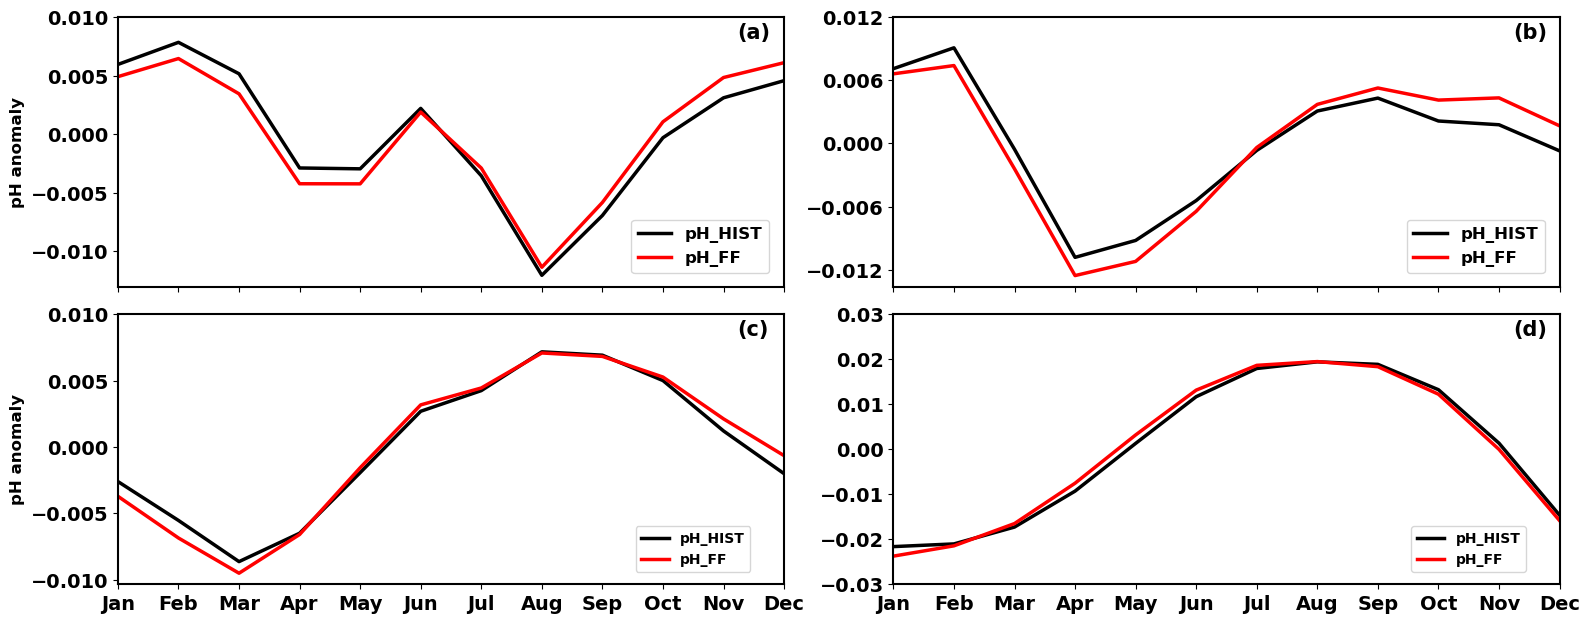

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.lines as mlines

regions = ['AS', 'BoB', 'CIO', 'SIO']
months = np.arange(12)
xtick_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


yticks_pH = [
    np.arange(-0.010,0.011, 0.005),
    np.arange(-0.012,0.013, 0.006),
    np.arange(-0.010,0.011, 0.005),
    np.arange(-0.03, 0.031, 0.01)
]


fig, axes = plt.subplots(2, 2, figsize=(16, 7), sharex=True)
axes = axes.flatten()
plt.rcParams['font.weight']='bold'

subplot_labels = ['(a)', '(b)', '(c)', '(d)']
for i, ax in enumerate(axes):
    ph_hist = ph_datasets[i*2]
    ph_ff = ph_datasets[i*2+1]

    l1, = ax.plot(months, ph_hist, '-', color='black', linewidth=2.5, label='pH_HIST')
    l2, = ax.plot(months, ph_ff, '-', color='red', linewidth=2.5, label='pH_FF')
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
    if i in [0, 2]:
         ax.set_ylabel('pH anomaly', color='black', fontweight='bold', fontsize=12)
 
    ax.set_yticks(yticks_pH[i])
    ax.set_xticks(months)
    ax.set_xticklabels(xtick_labels, fontweight='bold', fontsize=14)
    ax.set_xlim(0, 11)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelcolor='black', labelsize=14)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')

    # Subplot label like (a), (b), etc.
    ax.text(0.93, 0.98, subplot_labels[i], transform=ax.transAxes,
            fontsize=15, fontweight='bold', va='top', ha='left')

    # Add legend inside subplot
    if i in [0, 1]:  # Subplots a and b
        ax.legend(
            loc='upper right',
            bbox_to_anchor=(0.99, 0.28),
            fontsize=12,
            # prop={'weight': 'bold'},
            frameon=True
        )
   
    else:  # Subplots c and d
        ax.legend(
            loc='lower right',
            bbox_to_anchor=(0.96, 0.02),
            fontsize=10,
            prop={'weight': 'bold'},
            frameon=True
        )


plt.tight_layout(rect=[0, 0.055, 1, 0.96])
# plt.savefig("seasonal_cycles_pH_IO_regions_ssp126_review_f2.png", dpi=300, bbox_inches='tight')

plt.show()
